# 8. Genes: names, cancer roles and literature

*Page 8 of 9.* [previous: 7. Gene clusters and pathway flow](https://robinson-vidva.github.io/mb-methylation-xai/07_gene_clusters_and_pathway_flow.html) | [index](https://robinson-vidva.github.io/mb-methylation-xai/) | [next: 9. Conclusions](https://robinson-vidva.github.io/mb-methylation-xai/09_conclusions.html)

The previous pages name genes by symbol. This page says what each gene is, whether it is a known
cancer gene, what the literature says about it in medulloblastoma, and which signalling pathways it
belongs to. It then reads every concordant change against that knowledge.

**Sources, all public.** Full names and the NCBI gene summary come from MyGene.info. Oncogene and tumour
suppressor status comes from two curated lists: the OncoKB cancer gene list (gene type: oncogene,
tumour suppressor, both, or neither) and the COSMIC Cancer Gene Census "role in cancer", read through
the Open Targets Platform together with the COSMIC cancer hallmarks. Pathway membership is Reactome,
also through Open Targets. Literature is a PubMed count of papers that mention the gene together with
medulloblastoma in title or abstract, and the three most relevant of those papers.

**The reading.** A promoter that loses methylation switches a gene on; a promoter that gains
methylation switches it off. Two combinations fit a causal story in cancer: an **oncogene switched
on** by hypomethylation, and a **tumour suppressor silenced** by hypermethylation. The other two, an
oncogene silenced or a tumour suppressor switched on, do not, and are more likely lineage markers
that happen to carry a cancer label from another tissue. Most concordant genes have no cancer role in
either list; for them the methylation change reports cell identity, not transformation.

In [1]:
import json
import pandas as pd
from IPython.display import Image, display
from pathlib import Path
TAB = Path('../results/tables')
FIG = Path('../results/figures')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 90)

In [2]:
ann = pd.read_csv(TAB / 'gene_annotation.csv', index_col=0)
summ = json.load(open(TAB / 'gene_annotation_summary.json'))
print('genes annotated:', summ['genes_annotated'], '| with a cancer role:', summ['with_cancer_role'])
pd.Series(summ['cancer_role_counts'], name='genes').to_frame()

genes annotated: 464 | with a cancer role: 46


,genes
none,418
oncogene,20
tumour suppressor,18
both,8


## 1. The reading per subgroup

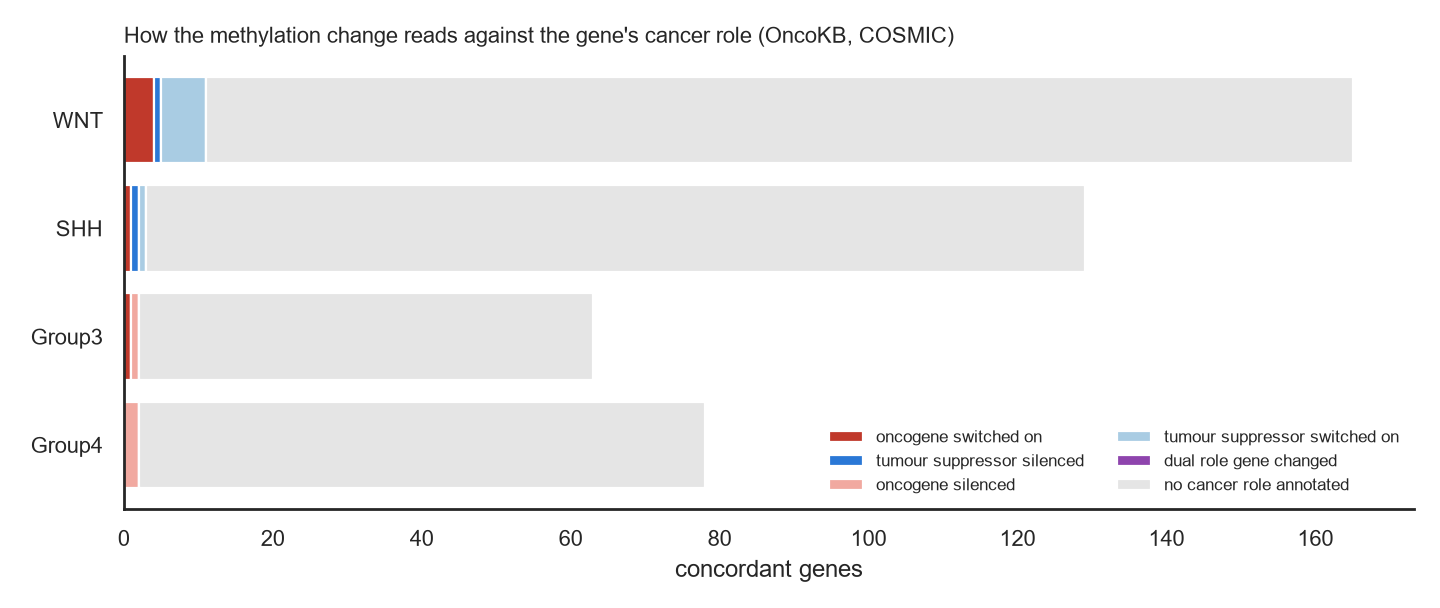

reading,no cancer role annotated,oncogene silenced,oncogene switched on,tumour suppressor silenced,tumour suppressor switched on
group,,,,,
WNT,154,0,4,1,6
SHH,126,0,1,1,1
Group3,61,1,1,0,0
Group4,76,2,0,0,0


In [3]:
display(Image(FIG / 'gene_roles_by_group.png'))
reg = pd.read_csv(TAB / 'gene_regulation_concordant.csv')
pd.crosstab(reg['group'], reg['reading']).reindex(['WNT', 'SHH', 'Group3', 'Group4'])

The genes that fit the causal story, per subgroup, with their names, the evidence source and the
number of medulloblastoma papers.

In [4]:
cols = ['group', 'gene', 'gene_name', 'direction', 'oncokb_gene_type', 'cgc_role_in_cancer', 'pubmed_medulloblastoma', 'reading']
fits = reg[reg['reading'].isin(['oncogene switched on', 'tumour suppressor silenced'])]
fits.sort_values(['group', 'pubmed_medulloblastoma'], ascending=[True, False])[cols].reset_index(drop=True)

,group,gene,gene_name,direction,oncokb_gene_type,cgc_role_in_cancer,pubmed_medulloblastoma,reading
0,Group3,IGF1,insulin like growth factor 1,"promoter hypomethylated, expression up",ONCOGENE,NaN,15,oncogene switched on
1,SHH,SCG5,secretogranin V,"promoter hypomethylated, expression up",ONCOGENE,NaN,0,oncogene switched on
2,SHH,APCDD1,APC down-regulated 1,"promoter hypermethylated, expression down",TSG,NaN,0,tumour suppressor silenced
3,WNT,SFRP1,secreted frizzled related protein 1,"promoter hypermethylated, expression down",TSG,NaN,10,tumour suppressor silenced
4,WNT,SYK,spleen associated tyrosine kinase,"promoter hypomethylated, expression up",ONCOGENE,NaN,2,oncogene switched on
5,WNT,STAT4,signal transducer and activator of transcription 4,"promoter hypomethylated, expression up",ONCOGENE,NaN,1,oncogene switched on
6,WNT,DDR2,discoidin domain receptor tyrosine kinase 2,"promoter hypomethylated, expression up",ONCOGENE,oncogene,0,oncogene switched on
7,WNT,SCG5,secretogranin V,"promoter hypomethylated, expression up",ONCOGENE,NaN,0,oncogene switched on


And the genes that carry a cancer label but change in the other direction. These are the ones to be
careful with: a label from leukaemia or breast cancer does not transfer to a cerebellar tumour.

In [5]:
against = reg[reg['reading'].isin(['oncogene silenced', 'tumour suppressor switched on', 'dual role gene changed'])]
against.sort_values(['group', 'pubmed_medulloblastoma'], ascending=[True, False])[cols].reset_index(drop=True)

,group,gene,gene_name,direction,oncokb_gene_type,cgc_role_in_cancer,pubmed_medulloblastoma,reading
0,Group3,SCG5,secretogranin V,"promoter hypermethylated, expression down",ONCOGENE,NaN,0,oncogene silenced
1,Group4,DDR2,discoidin domain receptor tyrosine kinase 2,"promoter hypermethylated, expression down",ONCOGENE,oncogene,0,oncogene silenced
2,Group4,SCG5,secretogranin V,"promoter hypermethylated, expression down",ONCOGENE,NaN,0,oncogene silenced
3,SHH,NDRG1,N-myc downstream regulated 1,"promoter hypomethylated, expression up",NaN,TSG; fusion,2,tumour suppressor switched on
4,WNT,EPHA3,EPH receptor A3,"promoter hypomethylated, expression up",TSG,NaN,4,tumour suppressor switched on
5,WNT,SLFN11,schlafen family member 11,"promoter hypomethylated, expression up",TSG,NaN,3,tumour suppressor switched on
6,WNT,ZNRF3,zinc and ring finger 3,"promoter hypomethylated, expression up",TSG,NaN,3,tumour suppressor switched on
7,WNT,RNF43,ring finger protein 43,"promoter hypomethylated, expression up",TSG,TSG,2,tumour suppressor switched on
8,WNT,APCDD1,APC down-regulated 1,"promoter hypomethylated, expression up",TSG,NaN,0,tumour suppressor switched on
9,WNT,ZFHX3,zinc finger homeobox 3,"promoter hypomethylated, expression up",TSG,TSG,0,tumour suppressor switched on


## 2. Signalling map

Concordant genes that have a cancer role or sit in a Reactome signal transduction pathway, per
subgroup. Position is the expression change, colour the direction of the methylation change, dot size
the number of medulloblastoma papers. Genes without any paper are the unexplored part of each list.

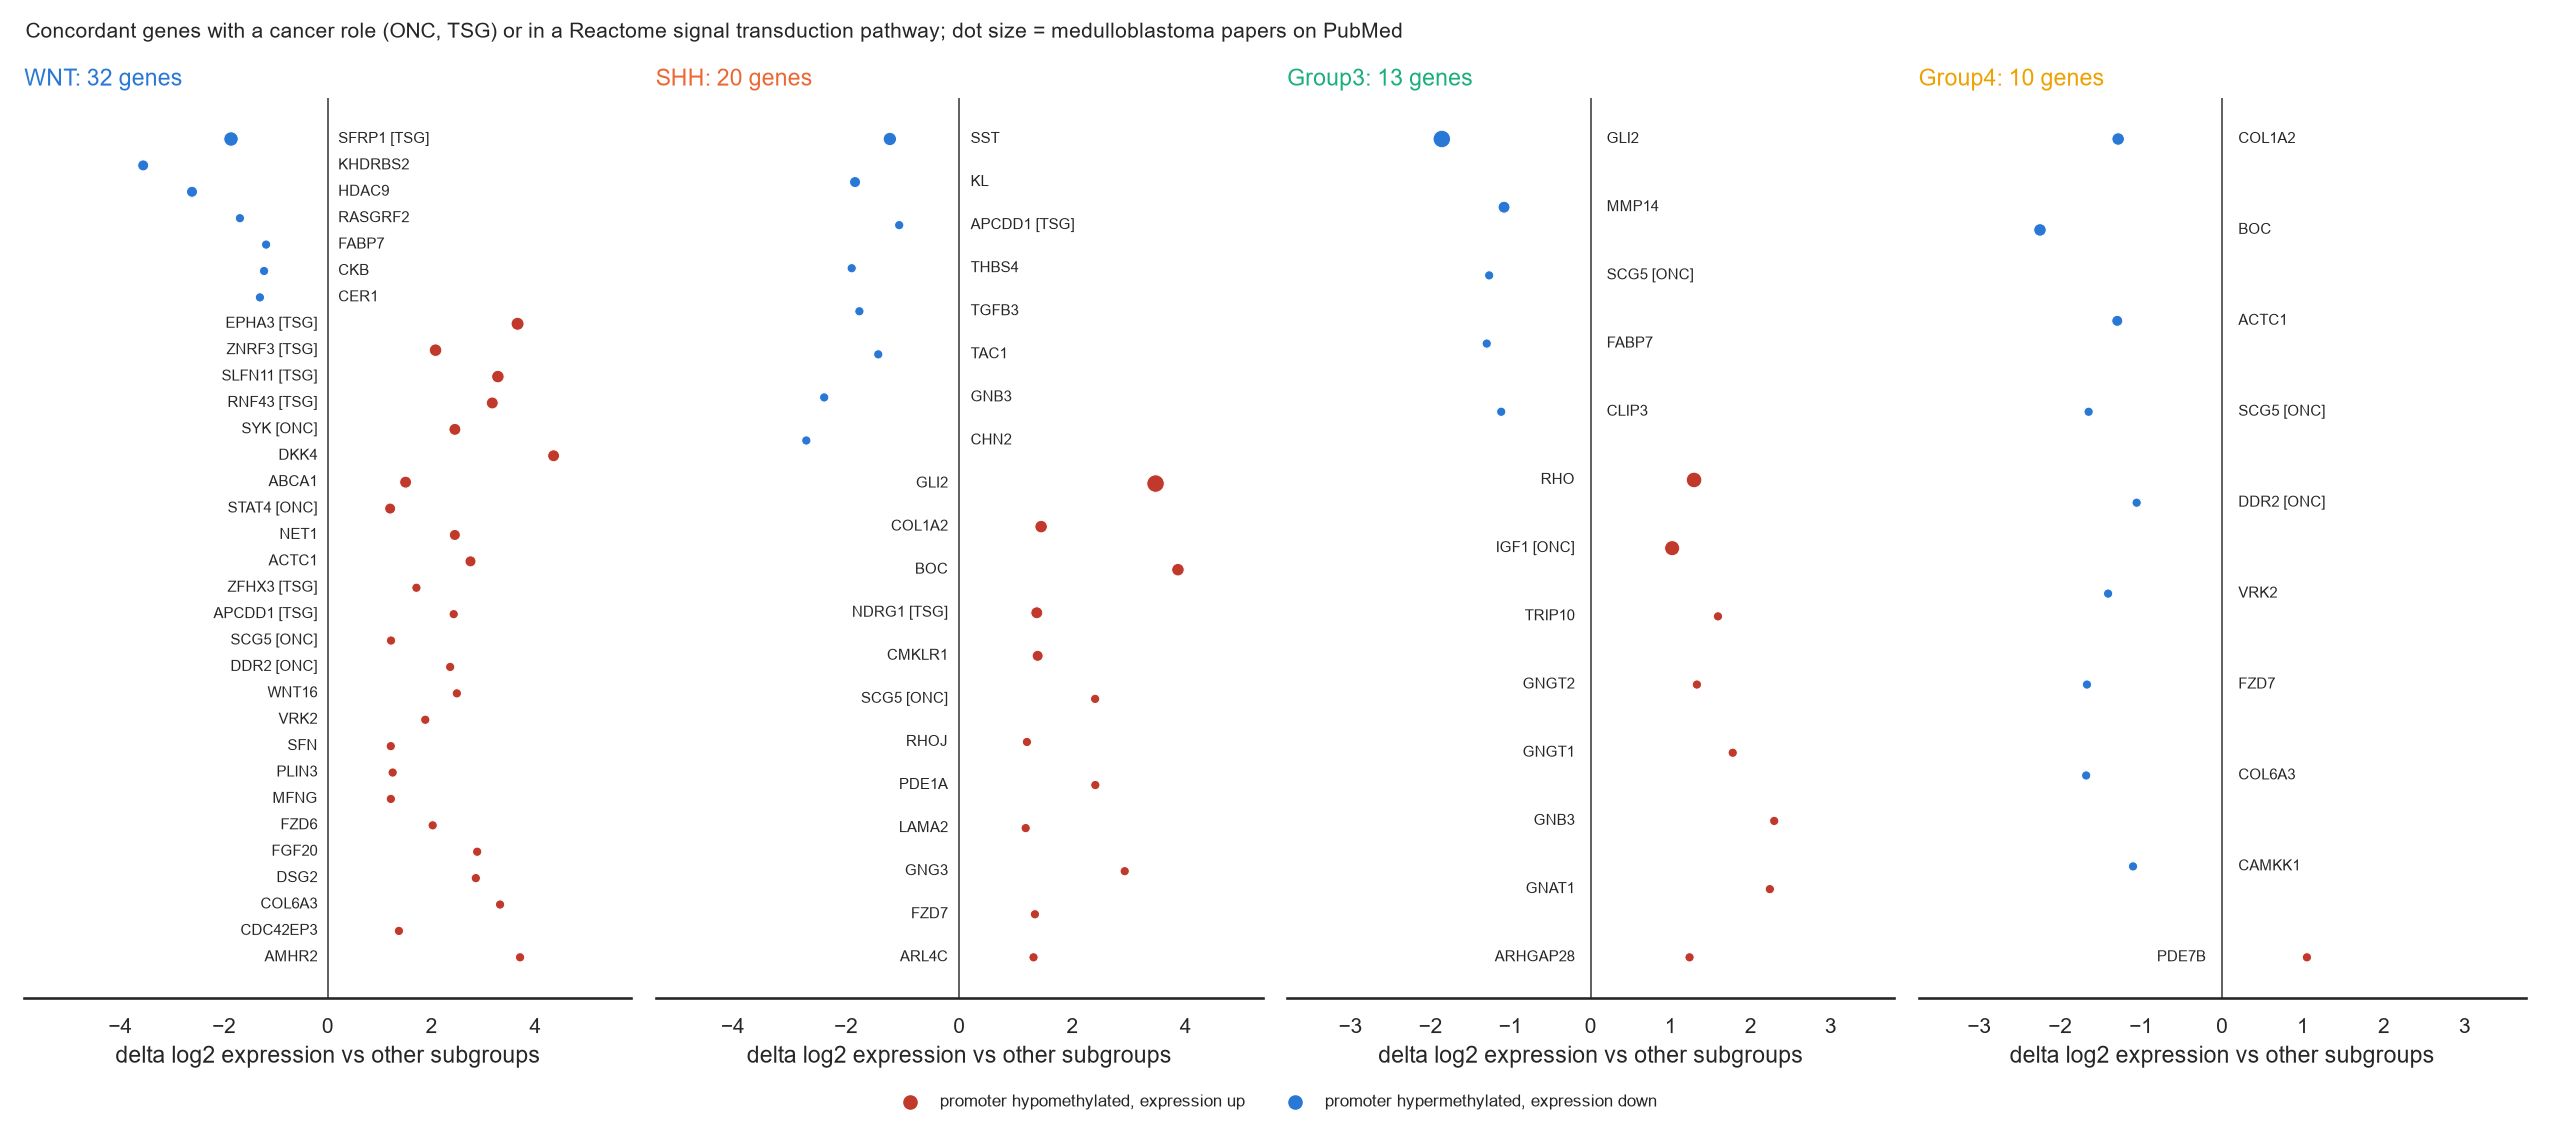

In [6]:
display(Image(FIG / 'signalling_map.png'))

## 3. The most studied genes in each subgroup

Literature count is a crude measure of what is known. A concordant gene with many medulloblastoma
papers is a known marker and the methylation result confirms it. A concordant gene with none is either
new or unimportant; the table of all genes at the end lets the reader decide.

In [7]:
pd.DataFrame({g: [f"{x[0]} ({int(x[1])})" for x in summ['most_cited_in_medulloblastoma_per_group'][g]] for g in ['WNT', 'SHH', 'Group3', 'Group4']})

,WNT,SHH,Group3,Group4
0,FAP (29),GLI2 (70),GLI2 (70),OTX2 (61)
1,SFRP1 (10),OTX2 (61),OTX2 (61),FAP (29)
2,IMPG2 (4),FAP (29),RHO (20),TF (18)
3,LOXL1 (4),SAG (12),TF (18),BOC (3)
4,EPHA3 (4),SST (5),IGF1 (15),COL1A2 (3)
5,PRAME (3),IMPG2 (4),SAG (12),EYA1 (3)
6,SLFN11 (3),BOC (3),IMPG2 (4),EOMES (2)
7,ZNRF3 (3),COL1A2 (3),PRAME (3),RBM24 (2)


In [8]:
lit = pd.read_csv(TAB / 'gene_literature_top.csv')
topg = reg.sort_values('pubmed_medulloblastoma', ascending=False).drop_duplicates('gene').head(12)['gene']
lit[lit['gene'].isin(topg) & (lit['rank'] == 1)].merge(reg.drop_duplicates('gene')[['gene', 'group', 'direction']], on='gene')[['group', 'gene', 'direction', 'year', 'title']].reset_index(drop=True)

,group,gene,direction,year,title
0,WNT,EPHA3,"promoter hypomethylated, expression up",2025,Beyond cell-cell contact: therapeutic potential of Eph signaling in central nervous sy...
1,Group4,FAP,"promoter hypermethylated, expression down",2023,Turcot Syndrome.
2,Group3,GLI2,"promoter hypermethylated, expression down",2021,The transcriptional landscape of Shh medulloblastoma.
3,Group3,IGF1,"promoter hypomethylated, expression up",2026,Targeting tumor-associated macrophage-induced IGF1/PI3K/Zic1 axis triggers SHH medullo...
4,Group3,IMPG2,"promoter hypomethylated, expression up",2026,Elucidating Tumorigenesis Mechanisms and Assessing Immunotherapeutic Efficacy in Patie...
5,WNT,LOXL1,"promoter hypomethylated, expression up",2018,LncRNA LOXL1-AS1 Promotes the Proliferation and Metastasis of Medulloblastoma by Activ...
6,Group3,OTX2,"promoter hypomethylated, expression up",2022,Failure of human rhombic lip differentiation underlies medulloblastoma formation.
7,Group3,RHO,"promoter hypomethylated, expression up",2019,Inhibition of Rho-Associated Kinase Suppresses Medulloblastoma Growth.
8,Group3,SAG,"promoter hypomethylated, expression up",2010,Small-molecule modulators of the Sonic Hedgehog signaling pathway.
9,WNT,SFRP1,"promoter hypermethylated, expression down",2007,Loss of suppressor-of-fused function promotes tumorigenesis.


## 4. The driver genes, annotated

The curated driver genes of each subgroup with the same annotation, for comparison. They are the
mutated or amplified genes; their methylation does not change (page 5), but their roles and literature
anchor the subgroup biology.

In [9]:
drv = pd.read_csv(TAB / 'therapy_driver_genes.csv')[['group', 'gene']]
drv.merge(ann[['gene_name', 'cancer_role', 'oncokb_gene_type', 'cgc_role_in_cancer', 'pubmed_medulloblastoma', 'reactome_top_level']], left_on='gene', right_index=True)

,group,gene,gene_name,cancer_role,oncokb_gene_type,cgc_role_in_cancer,pubmed_medulloblastoma,reactome_top_level
0,WNT,CTNNB1,catenin beta 1,oncogene,ONCOGENE,fusion; oncogene,68,Cell-Cell communication; Cellular responses to stimuli; Chromatin organization; Develo...
1,WNT,DDX3X,DEAD-box helicase 3 X-linked,tumour suppressor,TSG,TSG,21,Disease; Immune System
2,WNT,SMARCA4,SWI/SNF related BAF chromatin remodeling complex subunit ATPase 4,tumour suppressor,TSG,TSG; fusion,26,Cell-Cell communication; Chromatin organization; Developmental Biology; Gene expressio...
3,WNT,TP53,tumor protein p53,both,TSG,TSG; fusion; oncogene,221,Cell Cycle; Cellular responses to stimuli; DNA Repair; Developmental Biology; Disease;...
4,WNT,KMT2D,lysine methyltransferase 2D,both,TSG,"Oncogene, TSG",12,Chromatin organization; Developmental Biology; Disease; Gene expression (Transcription...
5,SHH,PTCH1,patched 1,tumour suppressor,TSG,TSG; fusion,233,Signal Transduction
6,SHH,SUFU,SUFU negative regulator of hedgehog signaling,tumour suppressor,TSG,TSG,106,Signal Transduction
7,SHH,SMO,"smoothened, frizzled class receptor",oncogene,ONCOGENE,oncogene,211,Organelle biogenesis and maintenance; Signal Transduction
8,SHH,GLI2,GLI family zinc finger 2,none,NaN,NaN,70,Gene expression (Transcription); Signal Transduction
9,SHH,MYCN,"MYCN proto-oncogene, bHLH transcription factor",oncogene,ONCOGENE,fusion; oncogene,176,Cell-Cell communication; Immune System; Signal Transduction


## 5. Reading the biology, subgroup by subgroup

**First, the overall count.** Of 464 annotated genes, 46 carry a curated cancer role. Of the 325
concordant genes, 262 have never been mentioned together with medulloblastoma on PubMed. Both numbers
say the same thing as page 7: the genes whose methylation defines a subgroup are mostly lineage genes,
not cancer genes. That is expected for a tumour classified by cell of origin, and it is the reason the
classifier works on FFPE blocks from another laboratory.

**WNT.** This is the subgroup where the reading has the most content, and the most instructive case
is the one that looks wrong. Six tumour suppressors are switched on: RNF43, ZNRF3, APCDD1, ZFHX3,
EPHA3 and SLFN11. RNF43 and ZNRF3 are E3 ubiquitin ligases that remove Frizzled receptors from the
cell surface; APCDD1 is a membrane Wnt inhibitor. All three are transcriptional targets of
beta-catenin, as are AXIN2, NKD1, NOTUM and DKK1 from page 7. They form the negative feedback
loop of the pathway: when Wnt signalling fires, the cell induces its own brakes. In WNT
medulloblastoma, CTNNB1 carries a mutation in the degradation motif, so beta-catenin is stable no
matter what happens at the receptor. The brakes are induced and have nothing to act on. The
methylation layer splits them in two: RNF43, ZNRF3, APCDD1 and SP5 are hypomethylated as well as
expressed, while AXIN2, NKD1, NOTUM and DKK1 are expressed with no promoter change. "Tumour
suppressor switched on" is here the signature of a pathway stuck on downstream of the point where
the suppressor acts. The one tumour suppressor silenced, SFRP1, a
secreted Wnt antagonist, is the classic promoter hypermethylation event of Wnt-driven cancers, and
has ten medulloblastoma papers. The oncogenes switched on, SYK and STAT4, are immune signalling
kinases and transcription factors with no medulloblastoma literature; they may reflect the immune
and stromal content of WNT tumours rather than the tumour cell, and are leads at most.

**SHH.** Almost nothing with a cancer label is concordant. GLI2 and BOC are the pathway-level hits
and carry the most literature (70 and 3 papers). APCDD1 silenced and NDRG1 switched on are the only
labelled genes; NDRG1 is a hypoxia and differentiation gene. The SHH concordant list is dominated by
genes of the desmoplastic stroma and of neuronal differentiation. The Hedgehog pathway itself is
activated by mutation, as page 7 shows, and the methylation layer adds the context of the lineage,
not the driver.

**Group 3.** IGF1 is the one oncogene switched on, with 15 medulloblastoma papers; insulin-like
growth factor signalling is an established growth signal in Group 3 models and a candidate target.
The rest of the labelled list is the photoreceptor program (RHO, GNAT1, GNGT1, GNGT2 in the
signalling map), which is lineage identity, and GLI2 and OTX2 silenced or switched on as the mirror
image of SHH and Group 4.

**Group 4.** No cancer-role gene fits the causal story. DDR2 and SCG5 are silenced, which reads as
lineage again. The most cited concordant genes, OTX2, EYA1, EOMES and RBM24, are developmental
transcription factors and RNA-binding proteins of the cerebellar lineage. Group 4 stays what the
literature says it is: the subgroup defined by its cell of origin rather than by a driver pathway,
with KDM6A, PRDM6 and SNCAIP as mutated or rearranged genes whose promoters do not change.

**Caveats on the counts.** PubMed counts use the gene symbol in title or abstract, so symbols that are
also common abbreviations are inflated: FAP (familial adenomatous polyposis, itself linked to
medulloblastoma), SAG (sagittal), SST, TF and RHO. Those counts should be read as upper bounds.
Twenty-nine symbols come from the 2011 Illumina manifest and are no longer current (C1orf61,
HIST1H3E, SEPP1 and others); they have no name in the table. Oncogene and tumour suppressor labels
come from pan-cancer curation and do not transfer automatically to a cerebellar tumour of childhood;
the WNT feedback genes are the proof.

## 6. Every annotated gene

The full table, one row per gene: name, which analyses it appears in, cancer role and sources,
hallmarks, Reactome pathways, PubMed counts, the Open Targets medulloblastoma association score and
the NCBI summary. Also in `results/tables/gene_annotation.csv`.

In [10]:
pd.set_option('display.max_rows', 500)
ann.sort_values('pubmed_medulloblastoma', ascending=False)[['gene_name', 'in_sets', 'cancer_role', 'oncokb_gene_type', 'cgc_role_in_cancer', 'pubmed_medulloblastoma', 'pubmed_cancer', 'reactome_top_level']]

,gene_name,in_sets,cancer_role,oncokb_gene_type,cgc_role_in_cancer,pubmed_medulloblastoma,pubmed_cancer,reactome_top_level
gene,,,,,,,,
SHH,sonic hedgehog signaling molecule,pathway_flow,none,NaN,NaN,1118,2415,Developmental Biology; Disease; Signal Transduction
MYC,"MYC proto-oncogene, bHLH transcription factor",driver; pathway_flow,oncogene,ONCOGENE,"oncogene, fusion",500,27277,Cell Cycle; Cell-Cell communication; Cellular responses to stimuli; Developmental Biol...
PTCH1,patched 1,driver; pathway_flow,tumour suppressor,TSG,TSG; fusion,233,910,Signal Transduction
TP53,tumor protein p53,driver,both,TSG,TSG; fusion; oncogene,221,23596,Cell Cycle; Cellular responses to stimuli; DNA Repair; Developmental Biology; Disease;...
SMO,"smoothened, frizzled class receptor",driver; pathway_flow,oncogene,ONCOGENE,oncogene,211,1289,Organelle biogenesis and maintenance; Signal Transduction
GLI1,GLI family zinc finger 1,pathway_flow,oncogene,ONCOGENE,NaN,186,1885,Signal Transduction
MYCN,"MYCN proto-oncogene, bHLH transcription factor",driver; pathway_flow,oncogene,ONCOGENE,fusion; oncogene,176,2907,Cell-Cell communication; Immune System; Signal Transduction
SUFU,SUFU negative regulator of hedgehog signaling,driver; pathway_flow,tumour suppressor,TSG,TSG,106,301,Signal Transduction
APC,APC regulator of Wnt signaling pathway,pathway_flow,tumour suppressor,TSG,TSG,78,13688,Disease; Metabolism of proteins; Programmed Cell Death; Signal Transduction


*Page 8 of 9.* [previous: 7. Gene clusters and pathway flow](https://robinson-vidva.github.io/mb-methylation-xai/07_gene_clusters_and_pathway_flow.html) | [index](https://robinson-vidva.github.io/mb-methylation-xai/) | [next: 9. Conclusions](https://robinson-vidva.github.io/mb-methylation-xai/09_conclusions.html)